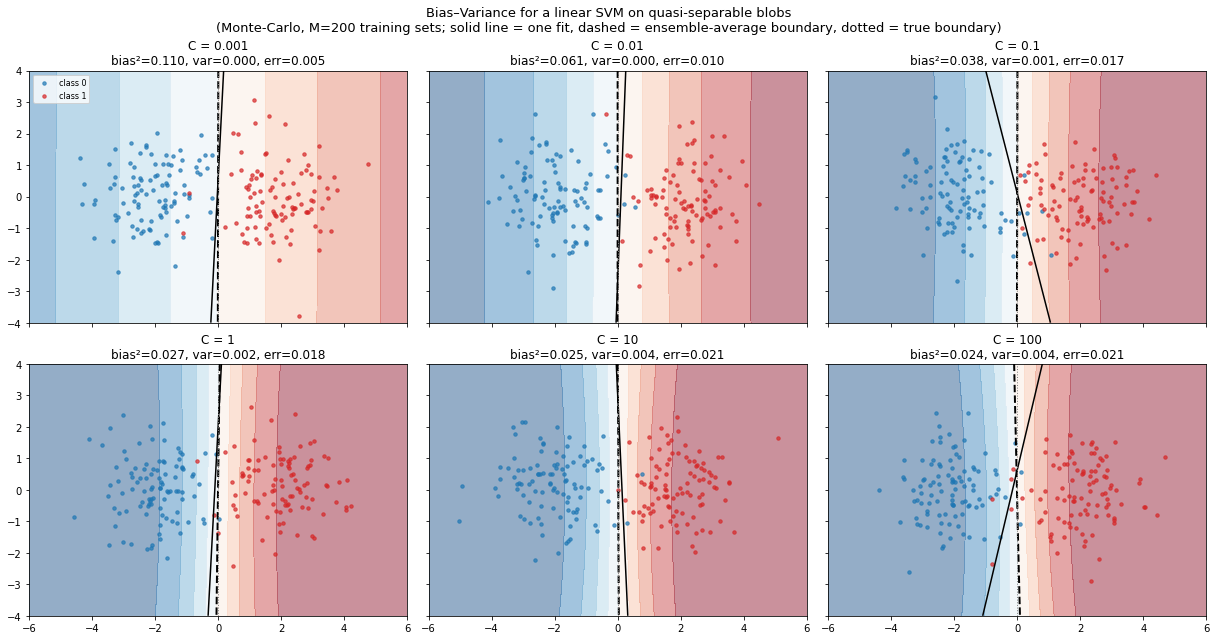

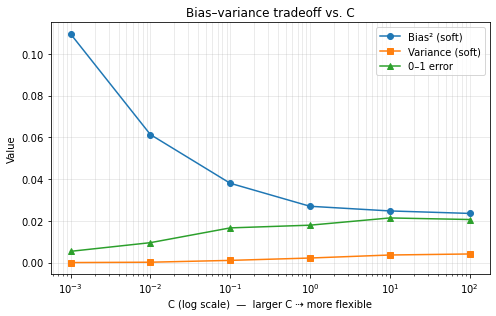

       C     bias^2   variance      err01
   0.001     0.1095     0.0000     0.0054
    0.01     0.0613     0.0002     0.0096
     0.1     0.0380     0.0011     0.0166
       1     0.0270     0.0022     0.0179
      10     0.0247     0.0037     0.0214
     100     0.0236     0.0041     0.0206


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import LinearSVC

rng = np.random.default_rng(0)

# ----------------------------------------------------------------------
# 1. Data-generating process: two quasi-separable Gaussian blobs
# ----------------------------------------------------------------------
def sample_dataset(n_per_class=100, sigma=1.0, sep=2.0):
    X0 = rng.normal(loc=(-sep, 0.0), scale=sigma, size=(n_per_class, 2))
    X1 = rng.normal(loc=( sep, 0.0), scale=sigma, size=(n_per_class, 2))
    X = np.vstack([X0, X1])
    y = np.r_[np.zeros(n_per_class, dtype=int),
              np.ones(n_per_class, dtype=int)]
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

# Dense test grid
gx, gy = np.meshgrid(np.linspace(-6, 6, 220),
                     np.linspace(-4, 4, 160))
X_test = np.c_[gx.ravel(), gy.ravel()]

# Bayes-optimal label for symmetric blobs at (±sep, 0): class 1 iff x > 0
y_star = (X_test[:, 0] > 0).astype(int)

# ----------------------------------------------------------------------
# 2. Monte-Carlo over C
# ----------------------------------------------------------------------
M = 200
Cs = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

results = {}
for C in Cs:
    scores = np.zeros((M, X_test.shape[0]))
    hard   = np.zeros((M, X_test.shape[0]), dtype=int)
    one_fit = None
    one_train = None

    for m in range(M):
        X_tr, y_tr = sample_dataset()
        clf = LinearSVC(C=C, max_iter=50000, random_state=0)
        clf.fit(X_tr, y_tr)
        s = clf.decision_function(X_test)
        scores[m] = s
        hard[m]   = (s > 0).astype(int)
        if m == 0:
            one_fit   = clf
            one_train = (X_tr, y_tr)

    # soft score -> probability via logistic map
    p_all = 1.0 / (1.0 + np.exp(-scores))
    p_bar = p_all.mean(axis=0)

    bias_sq  = ((p_bar - y_star) ** 2).mean()
    variance = p_all.var(axis=0).mean()
    err01    = (hard != y_star[None, :]).mean()

    results[C] = dict(scores=scores, p_all=p_all, p_bar=p_bar,
                      bias_sq=bias_sq, variance=variance, err01=err01,
                      one_fit=one_fit, one_train=one_train)

# ----------------------------------------------------------------------
# 3. Visualization — six panels, one per C
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(17, 9), sharex=True, sharey=True)
axes = axes.ravel()

for ax, C in zip(axes, Cs):
    r = results[C]
    X_tr, y_tr = r["one_train"]

    # background: ensemble-averaged P(y=1)
    Z = r["p_bar"].reshape(gx.shape)
    ax.contourf(gx, gy, Z, levels=np.linspace(0, 1, 11),
                cmap="RdBu_r", alpha=0.45)
    ax.contour(gx, gy, Z, levels=[0.5], colors="k", linewidths=2,
               linestyles="--")
    # boundary of THIS panel's single fit
    Zs = r["one_fit"].decision_function(X_test).reshape(gx.shape)
    ax.contour(gx, gy, Zs, levels=[0], colors="k", linewidths=1.5)

    ax.scatter(X_tr[y_tr == 0, 0], X_tr[y_tr == 0, 1],
               s=12, color="C0", alpha=0.7, label="class 0")
    ax.scatter(X_tr[y_tr == 1, 0], X_tr[y_tr == 1, 1],
               s=12, color="C3", alpha=0.7, label="class 1")

    ax.axvline(0, color="gray", ls=":", lw=1)   # true Bayes boundary
    ax.set_title(f"C = {C:g}\n"
                 f"bias²={r['bias_sq']:.3f}, var={r['variance']:.3f}, "
                 f"err={r['err01']:.3f}")
    ax.set_xlim(-6, 6); ax.set_ylim(-4, 4)
    ax.set_aspect("equal")

axes[0].legend(fontsize=8, loc="upper left")

fig.suptitle(f"Bias–Variance for a linear SVM on quasi-separable blobs\n"
             f"(Monte-Carlo, M={M} training sets; solid line = one fit, "
             f"dashed = ensemble-average boundary, dotted = true boundary)",
             fontsize=13)
fig.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 4. Summary figure: bias², variance, 0–1 error vs. C
# ----------------------------------------------------------------------
C_arr    = np.array(Cs)
bias_arr = np.array([results[C]["bias_sq"]  for C in Cs])
var_arr  = np.array([results[C]["variance"] for C in Cs])
err_arr  = np.array([results[C]["err01"]    for C in Cs])

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(C_arr, bias_arr, "o-", label="Bias² (soft)")
ax.plot(C_arr, var_arr,  "s-", label="Variance (soft)")
ax.plot(C_arr, err_arr,  "^-", label="0–1 error")
ax.set_xscale("log")
ax.set_xlabel("C (log scale)  —  larger C ⇢ more flexible")
ax.set_ylabel("Value")
ax.set_title("Bias–variance tradeoff vs. C")
ax.legend()
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout()
plt.show()

# ----------------------------------------------------------------------
# 5. Numeric summary
# ----------------------------------------------------------------------
print(f"{'C':>8} {'bias^2':>10} {'variance':>10} {'err01':>10}")
for C in Cs:
    r = results[C]
    print(f"{C:>8g} {r['bias_sq']:>10.4f} {r['variance']:>10.4f} "
          f"{r['err01']:>10.4f}")